# Locate and Label: Two-Stage Identifier for Nested NER
**Shen et al., ACL 2021 — implemented for GENIA dataset**

This notebook adapts the Locate and Label model exactly to the same data pipeline used in the BiLSTM-CRF baseline:
- Same `genia_train_dev.json` / `vocab.json` / `vocab_embed_bio.npy`
- Same 90/10 train/dev split with `random_state=42`
- Same entity types: DNA, RNA, cell_type, protein, cell_line
- Metrics: Precision, Recall, F1, Exact Match (EM)

In [1]:
!pip install torch torchvision torchaudio
!pip install tqdm scikit-learn
!pip install -q --upgrade transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 105.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 642.6/642.6 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 77.5 MB/s eta 0:00:00


## 1. Imports

In [2]:
import json
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from sklearn.model_selection import train_test_split
from tqdm import tqdm, trange
from collections import defaultdict
from typing import List, Tuple, Dict, Optional, NamedTuple
from transformers import AutoModel, AutoTokenizer

from torch.optim import AdamW
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Data Loading

In [3]:
with open("/kaggle/input/datasets/rahul2027/geniadataset/genia/genia_train_dev.json") as f:
    data = json.load(f)

def filter_empty(data):
    return [x for x in data if len(x["entities"]) > 0]

train_data, dev_data = train_test_split(data, test_size=0.1, random_state=42)
train_data = filter_empty(train_data)
dev_data   = filter_empty(dev_data)

print(f"Train sentences : {len(train_data)}")
print(f"Dev   sentences : {len(dev_data)}")

with open("/kaggle/input/datasets/rahul2027/geniadataset/genia/genia_test.json") as f:
    test_data = json.load(f)
test_data = filter_empty(test_data)
print(f"Test  sentences : {len(test_data)}")


Train sentences : 13446
Dev   sentences : 1499
Test  sentences : 1618


## 3. Entity Setup & Utilities

In [4]:
ENTITY_TYPES = ["DNA", "RNA", "cell_type", "protein", "cell_line"]

cat2id = {"NONE": 0}
for t in ENTITY_TYPES:
    cat2id[t] = len(cat2id)
id2cat = {v: k for k, v in cat2id.items()}
NUM_ENTITY_CLASSES = len(ENTITY_TYPES)

print(f"Category map: {cat2id}")

def load_gt_entities(entities, seq_len):
    """Return list of (start, end_inclusive, cat_id), skipping bad spans."""
    out = []
    for e in entities:
        s, e_ex, t = e["start"], e["end"], e["type"]
        e_inc = e_ex - 1          # exclusive → inclusive
        if s >= seq_len or e_inc >= seq_len or e_inc < s:
            continue
        cat = cat2id.get(t, 0)
        if cat == 0:
            continue
        out.append((s, e_inc, cat))
    return out


Category map: {'NONE': 0, 'DNA': 1, 'RNA': 2, 'cell_type': 3, 'protein': 4, 'cell_line': 5}


## 4. Span Utility Functions

In [5]:
def span_iou(a_s, a_e, b_s, b_e):
    """IoU between two spans with inclusive ends."""
    inter = max(0, min(a_e, b_e) - max(a_s, b_s) + 1)
    union = (a_e - a_s + 1) + (b_e - b_s + 1) - inter
    return inter / union if union > 0 else 0.0


def generate_seed_spans(seq_len, windows):
    """
    Enumerate all (start, end_inclusive) pairs whose length is in `windows`.
    Table 6 (GENIA): windows = [1..10]
    """
    spans = []
    for length in windows:
        for start in range(seq_len - length + 1):
            spans.append((start, start + length - 1))
    return spans


def assign_span_targets(seed_spans, gt_entities, alpha):
    """
    §2.2: Pair each seed span with its best-IoU ground-truth entity.
    Returns:
      filter_labels : list[int]
      reg_targets   : list[(Δl,Δr)] or None
      best_ious     : list[float]
      cat_ids       : list[int]
      matched_gt_idx: list[int]  (index of matched GT, -1 if none)
    """
    filter_labels, reg_targets, best_ious, cat_ids, matched_gt_idx = [], [], [], [], []

    for (ss, se) in seed_spans:

        if not gt_entities:
            filter_labels.append(0)
            reg_targets.append(None)
            best_ious.append(0.0)
            cat_ids.append(0)
            matched_gt_idx.append(-1)
            continue

        best_iou = 0.0
        best_idx = -1

        for j, ent in enumerate(gt_entities):
            iou = span_iou(ss, se, ent[0], ent[1])
            if iou > best_iou:
                best_iou = iou
                best_idx = j

        best_ious.append(best_iou)

        if best_iou >= alpha:
            best_ent = gt_entities[best_idx]

            filter_labels.append(1)
            reg_targets.append((
                float(best_ent[0] - ss),
                float(best_ent[1] - se)
            ))
            cat_ids.append(best_ent[2])
            matched_gt_idx.append(best_idx)

        else:
            filter_labels.append(0)
            reg_targets.append(None)
            cat_ids.append(0)
            matched_gt_idx.append(-1)

    return filter_labels, reg_targets, best_ious, cat_ids, matched_gt_idx

def soft_weight(iou, alpha, eta=1.0):
    """Equation (11) from the paper."""
    if iou >= alpha:
        return iou ** eta
    else:
        return (1.0 - iou) ** eta

print("Span utilities loaded.")

Span utilities loaded.


## 4. BioBERT Tokenizer & Dataset

In [6]:
BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.2"

class BioBERTTokenEncoder(nn.Module):
    """
    §2.1 (modified): Uses BioBERT as the token encoder instead of
    word-emb + char-BiLSTM + BiLSTM. BioBERT produces one contextual
    hidden vector per token (via word-piece → word alignment).
    """
    def __init__(self, biobert_name=BIOBERT_MODEL, dropout=0.1, freeze_layers=8):
        super().__init__()
        self.bert       = AutoModel.from_pretrained(biobert_name)
        self.hidden_dim = self.bert.config.hidden_size   # 768
        self.dropout    = nn.Dropout(dropout)

        # Freeze lower BERT layers to speed up training
        if freeze_layers > 0:
            for mod in [self.bert.embeddings,
                        *self.bert.encoder.layer[:freeze_layers]]:
                for p in mod.parameters():
                    p.requires_grad = False

    def forward(self, input_ids, attn_mask, wp_to_token, lengths):
        """
        input_ids   : (B, S_wp)
        attn_mask   : (B, S_wp)
        wp_to_token : (B, S_wp)  value j = original token j; -1 for CLS/SEP/pad
        lengths     : (B,)
        Returns     : (B, S_max, 768) token-level hidden states
        """
        B     = input_ids.size(0)
        S_max = lengths.max().item()

        wp_h = self.bert(input_ids=input_ids,
                         attention_mask=attn_mask).last_hidden_state  # (B,S_wp,768)
        wp_h = self.dropout(wp_h)

        # Average word-piece vectors → one vector per original token
        tok_h  = torch.zeros(B, S_max, self.hidden_dim, device=input_ids.device)
        counts = torch.zeros(B, S_max, 1,               device=input_ids.device)
        mask   = (wp_to_token >= 0)
        for b in range(B):
            tok_idx = wp_to_token[b][mask[b]]
            hidden  = wp_h[b][mask[b]]
            tok_h[b].index_add_(0, tok_idx, hidden)
            ones = torch.ones(tok_idx.size(0), 1, device=input_ids.device)
            counts[b].index_add_(0, tok_idx, ones)

        return tok_h / counts.clamp(min=1)   # (B, S_max, 768)


TokenEncoder = BioBERTTokenEncoder   # alias kept for compatibility
print("BioBERTTokenEncoder defined.")

BioBERTTokenEncoder defined.


In [7]:
from transformers import AutoTokenizer

# ── BioBERT tokenizer setup (replaces char vocabulary) ───────────────

biobert_tokenizer = AutoTokenizer.from_pretrained(BIOBERT_MODEL)

MAX_WP_LEN = 512  # max word-piece length for BioBERT


def tokenize_for_biobert(tokens):
    """
    Tokenises a pre-tokenised sentence for BioBERT using is_split_into_words=True.

    Returns:
        input_ids   : list[int]  (includes [CLS]/[SEP])
        attn_mask   : list[int]  (1 for real tokens, 0 for padding)
        wp_to_tok   : list[int]  (word-piece index → original token index,
                                 -1 for [CLS]/[SEP])
    """

    enc = biobert_tokenizer(
        tokens,
        is_split_into_words=True,
        max_length=MAX_WP_LEN,
        truncation=True,
        add_special_tokens=True,
    )

    input_ids = enc["input_ids"]
    attn_mask = enc["attention_mask"]

    # None for CLS/SEP, int otherwise
    word_ids = enc.word_ids()

    wp_to_tok = [-1 if wid is None else wid for wid in word_ids]

    return input_ids, attn_mask, wp_to_tok


print(f"BioBERT tokenizer ready. Vocab size: {biobert_tokenizer.vocab_size}")

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

BioBERT tokenizer ready. Vocab size: 28996


In [8]:
class GENIADataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        s      = self.data[idx]
        tokens = s["tokens"]
        n      = len(tokens)

        input_ids, attn_mask, wp_to_tok = tokenize_for_biobert(tokens)
        gt = load_gt_entities(s["entities"], n)

        return {
            "input_ids":   torch.tensor(input_ids,   dtype=torch.long),
            "attn_mask":   torch.tensor(attn_mask,   dtype=torch.long),
            "wp_to_token": torch.tensor(wp_to_tok,   dtype=torch.long),
            "gt":          gt,
            "length":      n,
        }

def collate_fn(batch):
    batch.sort(key=lambda x: x["length"], reverse=True)
    max_wp  = max(b["input_ids"].size(0) for b in batch)
    bsz     = len(batch)

    input_ids   = torch.zeros(bsz, max_wp, dtype=torch.long)
    attn_mask   = torch.zeros(bsz, max_wp, dtype=torch.long)
    wp_to_token = torch.full((bsz, max_wp), -1, dtype=torch.long)
    lengths     = torch.tensor([b["length"] for b in batch], dtype=torch.long)

    for i, b in enumerate(batch):
        wp_len = b["input_ids"].size(0)
        input_ids[i,   :wp_len] = b["input_ids"]
        attn_mask[i,   :wp_len] = b["attn_mask"]
        wp_to_token[i, :wp_len] = b["wp_to_token"]

    return {
        "input_ids":   input_ids,
        "attn_mask":   attn_mask,
        "wp_to_token": wp_to_token,
        "lengths":     lengths,
        "gt":          [b["gt"] for b in batch],
    }

BATCH_SIZE = 8
train_loader = DataLoader(GENIADataset(train_data), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
dev_loader   = DataLoader(GENIADataset(dev_data),   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(GENIADataset(test_data),  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
print(f"Batches - Train: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")


Batches - Train: 1681, Dev: 188, Test: 203


## 5. Model Components
### 5a. Token Encoder  (§2.1) — **BioBERT**
Pre-trained `dmis-lab/biobert-base-cased-v1.2` produces contextual token embeddings.
Word-pieces are averaged back to word-level representations.
Lower 8 layers are frozen; top 4 layers are fine-tuned.

### 5b. Span Representation Helpers — **Attention Pool**
Replaces the original hard max-pool with a learned single-head attention pooling.
A linear scorer assigns per-token weights within the span; the representation
is the softmax-weighted sum of token hidden states.

In [9]:
class SpanAttentionPool(nn.Module):
    """
    Learned single-head attention pooling over a span.
    Replaces the hard max-pool used in the original paper; the model
    learns per-token attention weights within each span.
    """
    def __init__(self, hidden_dim):
        super().__init__()
        self.score = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h, s, e, seq_len):
        """
        h       : (S, d)   token hidden states for one sentence
        s, e    : int      inclusive span boundaries
        Returns : (d,)
        """
        s = max(0, min(int(s), seq_len - 1))
        e = max(s, min(int(e), seq_len - 1))
        span_h = h[s:e+1]                             # (span_len, d)
        attn_w = torch.softmax(self.score(span_h).squeeze(-1), dim=0)  # (span_len,)
        return (attn_w.unsqueeze(-1) * span_h).sum(0) # (d,)


# Global singleton — initialised in LocateAndLabel.__init__
_attn_pool: Optional[SpanAttentionPool] = None

def init_attn_pool(hidden_dim: int):
    global _attn_pool
    _attn_pool = SpanAttentionPool(hidden_dim)


def attn_pool_span(h, s, e, seq_len):
    """Attention-pool h[s:e+1].  Fallback: max-pool if not yet initialised."""
    if _attn_pool is None:
        s = max(0, min(s, seq_len - 1))
        e = max(s, min(e, seq_len - 1))
        return h[s:e+1].max(dim=0).values
    return _attn_pool(h, s, e, seq_len)


def get_span_rep_filter(h, starts, ends, seq_len):
    """
    §2.3 filter branch: [attn_pool ; h_start ; h_end]  → (N, 3d)
    Uses INNER boundary tokens.  Attention pooling replaces max-pool.
    """
    N = starts.shape[0]
    pools = torch.stack([
        attn_pool_span(h, starts[i].item(), ends[i].item(), seq_len)
        for i in range(N)])
    s_cl = starts.clamp(0, seq_len - 1)
    e_cl = torch.max(ends.clamp(0, seq_len - 1), s_cl)
    return torch.cat([pools, h[s_cl], h[e_cl]], dim=-1)   # (N, 3d)


def get_span_rep_regressor(h, starts, ends, seq_len):
    """
    §2.3 regressor branch: [attn_pool ; h_{start-1} ; h_{end+1}]  → (N, 3d)
    Uses OUTER boundary tokens (Eq. 4).  Attention pooling replaces max-pool.
    """
    N = starts.shape[0]
    pools = torch.stack([
        attn_pool_span(h, starts[i].item(), ends[i].item(), seq_len)
        for i in range(N)])
    out_s = (starts - 1).clamp(0, seq_len - 1)
    out_e = (ends   + 1).clamp(0, seq_len - 1)
    return torch.cat([pools, h[out_s], h[out_e]], dim=-1)  # (N, 3d)


print("Attention-pool span helpers loaded.")

Attention-pool span helpers loaded.


### 5c. Span Proposal Module  (§2.3)

In [10]:
def make_mlp(in_dim, out_dim):
    """Two-layer MLP with GELU activation (§2.3)."""
    return nn.Sequential(
        nn.Linear(in_dim, in_dim),
        nn.GELU(),
        nn.Linear(in_dim, out_dim),
    )


class SpanProposalModule(nn.Module):
    """
    §2.3: Two branches sharing the same sentence hidden states h.
      Filter    : decides which seed spans are proposals  (binary)
      Regressor : predicts (Δl, Δr) boundary offsets
    """
    def __init__(self, hidden_dim, dropout=0.5):
        super().__init__()
        d = hidden_dim
        self.dropout    = nn.Dropout(dropout)
        self.filter_mlp = make_mlp(3 * d, 1)    # → scalar logit
        self.reg_mlp    = make_mlp(3 * d, 2)    # → (Δl, Δr)

    def forward(self, h, starts, ends, seq_len):
        """
        h      : (S, d)  single-sentence hidden states
        starts : (N,)  seed span starts
        ends   : (N,)  seed span ends (inclusive)
        → filter_logits (N,), offsets (N, 2)
        """
        h_f = self.dropout(get_span_rep_filter(h, starts, ends, seq_len))
        h_r = self.dropout(get_span_rep_regressor(h, starts, ends, seq_len))
        return self.filter_mlp(h_f).squeeze(-1), self.reg_mlp(h_r)

### 5d. Entity Classifier Module  (§2.4)

In [11]:
class EntityClassifier(nn.Module):
    """
    §2.4: Re-pool the boundary-adjusted spans and classify into
    NUM_ENTITY_CLASSES + 1 categories (index 0 = NONE).
    """
    def __init__(self, hidden_dim, num_classes, dropout=0.5):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.cls_mlp = make_mlp(3 * hidden_dim, num_classes)

    def forward(self, h, starts, ends, seq_len):
        """
        h      : (S, d)
        starts : (N,) adjusted starts
        ends   : (N,) adjusted ends
        → logits (N, num_classes)
        """
        h_cls = self.dropout(get_span_rep_filter(h, starts, ends, seq_len))
        return self.cls_mlp(h_cls)

## 8. Full Model

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class LocateAndLabel(nn.Module):
    """
    Two-stage nested NER model (Shen et al., ACL 2021).
    Configured for GENIA dataset using Table 6 hyper-parameters.
    """

    def __init__(
        self,
        num_entity_classes,
        char_emb_dim=25,
        char_hidden=50,
        bilstm_hidden=768,
        windows=None,
        alpha1=0.7,
        alpha2=1.0,
        eta=1.0,
        gamma=2.0,
        lambda1=1.0,
        lambda2=0.1,
        lambda3=1.0,
        nms_iou_thr=0.7,
        nms_decay=0.9,
        score_thr=0.45,
        dropout=0.5,
    ):
        super().__init__()

        self.windows = windows if windows else list(range(1, 11))

        self.alpha1 = alpha1
        self.alpha2 = alpha2
        self.eta = eta
        self.gamma = gamma

        self.lambda1 = lambda1
        self.lambda2 = lambda2
        self.lambda3 = lambda3

        self.nms_iou_thr = nms_iou_thr
        self.nms_decay = nms_decay
        self.score_thr = score_thr

        self.num_classes = num_entity_classes + 1  # include "none"

        # Encoder
        self.encoder = TokenEncoder(dropout=dropout)

        d = bilstm_hidden

        self.proposal = SpanProposalModule(d, dropout)
        self.classifier = EntityClassifier(d, self.num_classes, dropout)

    # ============================
    # Training Forward
    # ============================
    def forward(self, input_ids, attn_mask, wp_to_token, lengths, gt_entities):
        B = input_ids.shape[0]
        dev = input_ids.device

        H = self.encoder(input_ids, attn_mask, wp_to_token, lengths)

        total_fl = total_rl = total_cl = 0.0
        n_sent = 0

        for b in range(B):
            seq_len = lengths[b].item()
            h = H[b, :seq_len]
            gt = gt_entities[b]

            seeds = generate_seed_spans(seq_len, self.windows)
            if not seeds:
                continue

            starts = torch.tensor([s[0] for s in seeds], dtype=torch.long, device=dev)
            ends = torch.tensor([s[1] for s in seeds], dtype=torch.long, device=dev)

            fl_lbl, reg_tgt, best_ious, cat_ids, matched_gt_idx = assign_span_targets(
                seeds, gt, self.alpha1
            )

            fl_lbl_t = torch.tensor(fl_lbl, dtype=torch.float, device=dev)
            ious_t = torch.tensor(best_ious, dtype=torch.float, device=dev)
            cat_ids_t = torch.tensor(cat_ids, dtype=torch.long, device=dev)

            # weights
            w_filter = torch.tensor(
                [soft_weight(iou, self.alpha1, self.eta) for iou in best_ious],
                dtype=torch.float,
                device=dev,
            )

            # Proposal
            filter_logits, offsets = self.proposal(h, starts, ends, seq_len)

            fl = focal_loss_with_weights(
                filter_logits, fl_lbl_t, w_filter, self.gamma
            )
            total_fl += fl

            # Regression
            pos_mask = fl_lbl_t.bool()

            if pos_mask.sum() > 0 and gt:
                pos_starts = starts[pos_mask]
                pos_ends = ends[pos_mask]
                pos_offsets = offsets[pos_mask]

                pos_indices = [i for i, f in enumerate(fl_lbl) if f == 1]

                gt_starts = torch.tensor(
                    [gt[matched_gt_idx[i]][0] for i in pos_indices],
                    dtype=torch.float,
                    device=dev
                )

                gt_ends = torch.tensor(
                    [gt[matched_gt_idx[i]][1] for i in pos_indices],
                    dtype=torch.float,
                    device=dev
                )

                gt_off = torch.tensor(
                    [reg_tgt[i] for i in pos_indices],
                    dtype=torch.float,
                    device=dev
                )

                rl = regression_loss(
                    pos_offsets,
                    gt_off,
                    pos_starts,
                    pos_ends,
                    gt_starts,
                    gt_ends
                )
                total_rl += rl

            # Classification
            cls_logits = self.classifier(h, starts, ends, seq_len)
            cl = cls_loss_weighted(cls_logits, cat_ids_t, w_filter)

            total_cl += cl
            n_sent += 1

        if n_sent == 0:
            z = torch.tensor(0.0, device=dev, requires_grad=True)
            return {"loss": z, "filter_loss": z, "reg_loss": z, "cls_loss": z}

        fl_mean = total_fl / n_sent
        rl_mean = total_rl / n_sent
        cl_mean = total_cl / n_sent

        loss = (
            self.lambda1 * fl_mean
            + self.lambda2 * rl_mean
            + self.lambda3 * cl_mean
        )

        return {
            "loss": loss,
            "filter_loss": fl_mean,
            "reg_loss": rl_mean,
            "cls_loss": cl_mean,
        }

    # ============================
    # Inference
    # ============================
    @torch.no_grad()
    def predict(self, input_ids, attn_mask, wp_to_token, lengths):
        B = input_ids.shape[0]
        H = self.encoder(input_ids, attn_mask, wp_to_token, lengths)

        all_preds = []

        for b in range(B):
            seq_len = lengths[b].item()
            h = H[b, :seq_len]

            seeds = generate_seed_spans(seq_len, self.windows)
            if not seeds:
                all_preds.append([])
                continue

            starts = torch.tensor([s[0] for s in seeds], device=h.device)
            ends = torch.tensor([s[1] for s in seeds], device=h.device)

            filter_logits, offsets = self.proposal(h, starts, ends, seq_len)

            mask = torch.sigmoid(filter_logits) > 0.5
            if mask.sum() == 0:
                all_preds.append([])
                continue

            starts = starts[mask]
            ends = ends[mask]
            offsets = offsets[mask]

            adj_s = (starts.float() + offsets[:, 0] + 0.5).long().clamp(0, seq_len - 1)
            adj_e = (ends.float() + offsets[:, 1] + 0.5).long().clamp(0, seq_len - 1)
            adj_e = torch.max(adj_e, adj_s)

            cls_logits = self.classifier(h, adj_s, adj_e, seq_len)
            probs = F.softmax(cls_logits, dim=-1)

            scores, labels = probs.max(dim=-1)

            preds = [
                SpanPred(adj_s[i].item(), adj_e[i].item(), labels[i].item(), scores[i].item())
                for i in range(labels.shape[0])
                if labels[i].item() != 0
            ]

            final = soft_nms(
                preds,
                self.nms_iou_thr,
                self.nms_decay,
                self.score_thr,
            )

            all_preds.append(final)

        return all_preds


print("LocateAndLabel model defined.")

LocateAndLabel model defined.


## 6. Loss Functions  (§2.5)

In [13]:
def focal_loss_with_weights(logits, labels, weights, gamma=2.0):
    """
    Eq. (12): IoU-weighted focal loss for the Span Proposal Filter.
    logits  : (N,) raw scores
    labels  : (N,) 0/1
    weights : (N,) soft weights from Eq. (11)
    """
    p = torch.sigmoid(logits)
    pos = -weights * labels.float() * (1 - p).pow(gamma) * (p + 1e-8).log()
    neg = -weights * (1 - labels.float()) * p.pow(gamma) * (1 - p + 1e-8).log()
    return (pos + neg).mean()


def regression_loss(pred_off, gt_off, p_starts, p_ends, gt_starts, gt_ends):
    """
    Eq. (13–15): SmoothL1 (boundary level) + overlap loss (span level).
    """
    if pred_off.shape[0] == 0:
        return torch.tensor(0., device=pred_off.device, requires_grad=True)

    # Boundary-level SmoothL1 (Eq. 14)
    l_f1 = F.smooth_l1_loss(pred_off, gt_off)

    # Span-level overlap loss (Eq. 15)
    adj_s = p_starts.float() + pred_off[:, 0]
    adj_e = p_ends.float()   + pred_off[:, 1]
    gt_s  = gt_starts.float()
    gt_e  = gt_ends.float()

    min_d = torch.min(adj_e, gt_e)
    max_d = torch.max(adj_e, gt_e)
    min_e = torch.min(adj_s, gt_s)
    max_e = torch.max(adj_s, gt_s)
    denom = (max_d - min_e).clamp(min=1e-6)
    l_olp = (1.0 - (min_d - max_e) / denom).clamp(min=0).mean()

    return l_f1 + l_olp


def cls_loss_weighted(logits, labels, weights):
    """Eq. (16): IoU-weighted cross-entropy for the Entity Classifier."""
    if logits.shape[0] == 0:
        return torch.tensor(0., device=logits.device, requires_grad=True)
    ce = F.cross_entropy(logits, labels, reduction="none")
    return (weights * ce).mean()

print("Loss functions loaded.")

Loss functions loaded.


## 7. Soft-NMS Decoding  (§2.6, Algorithm 1)

In [14]:
class SpanPred(NamedTuple):
    start: int
    end:   int      # inclusive
    label: int
    score: float


def soft_nms(spans, iou_thr=0.7, decay=0.9, score_thr=0.1):
    """
    §2.6, Algorithm 1.  Parameters from Table 6 (GENIA column):
      k=0.7, u=0.9, δ=0.45
    """
    if not spans:
        return []
    spans = sorted(spans, key=lambda x: x.score, reverse=True)
    result = []
    while spans:
        best = spans[0]
        result.append(best)
        remaining = []
        for s in spans[1:]:
            iou = span_iou(best.start, best.end, s.start, s.end)
            new_score = s.score * decay if iou >= iou_thr else s.score
            if new_score > score_thr:
                remaining.append(SpanPred(s.start, s.end, s.label, new_score))
        remaining.sort(key=lambda x: x.score, reverse=True)
        spans = remaining
    return result

print("Soft-NMS loaded.")

Soft-NMS loaded.


## 10. Metrics
Strict evaluation (boundary + label must both match), plus per-entity-type breakdown.

In [15]:
def compute_metrics(pred_spans_all, gold_spans_all, id2cat):
    """
    pred_spans_all : list[list[SpanPred]]    one inner list per sentence
    gold_spans_all : list[list[(s,e,cat)]]   one inner list per sentence

    Returns overall and per-type dicts with keys:
      precision, recall, f1, exact_match (EM)
    
    - Precision  = TP / (TP + FP)
    - Recall     = TP / (TP + FN)
    - F1         = harmonic mean of P and R
    - Exact Match (EM) = fraction of gold entities exactly predicted
      (a sentence-level EM = 1 only if its predicted set == gold set)
    """
    assert len(pred_spans_all) == len(gold_spans_all)

    overall_tp = overall_fp = overall_fn = 0
    per_type   = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})
    em_count   = 0   # sentences where pred == gold exactly
    n_sent     = len(pred_spans_all)

    for preds, golds in zip(pred_spans_all, gold_spans_all):
        # Convert to comparable sets of tuples (start, end_inc, cat_id)
        pred_set = {(p.start, p.end, p.label) for p in preds}
        gold_set = {(g[0], g[1], g[2])        for g in golds}

        # Exact match for this sentence
        if pred_set == gold_set:
            em_count += 1

        tp = pred_set & gold_set
        fp = pred_set - gold_set
        fn = gold_set - pred_set

        overall_tp += len(tp)
        overall_fp += len(fp)
        overall_fn += len(fn)

        for s, e, cat in tp:
            per_type[id2cat.get(cat, str(cat))]["tp"] += 1
        for s, e, cat in fp:
            per_type[id2cat.get(cat, str(cat))]["fp"] += 1
        for s, e, cat in fn:
            per_type[id2cat.get(cat, str(cat))]["fn"] += 1

    def prf(tp, fp, fn):
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2 * p * r / (p + r + 1e-9)
        return p, r, f1

    p, r, f1 = prf(overall_tp, overall_fp, overall_fn)
    em        = em_count / n_sent if n_sent > 0 else 0.

    overall = {"precision": p, "recall": r, "f1": f1, "exact_match": em,
               "tp": overall_tp, "fp": overall_fp, "fn": overall_fn,
               "sentences": n_sent, "em_count": em_count}

    per_type_out = {}
    for cat, counts in per_type.items():
        cp, cr, cf = prf(counts["tp"], counts["fp"], counts["fn"])
        per_type_out[cat] = {"precision": cp, "recall": cr, "f1": cf,
                              **counts}

    return overall, per_type_out


def print_metrics(overall, per_type, epoch=None, loss=None):
    header = f"  Epoch {epoch}  " if epoch is not None else "  "
    if loss is not None:
        header += f"Train Loss: {loss:.4f}  "

    print("\n" + "─" * 65)
    print(header)
    print(f"  Overall  →  P: {overall['precision']:.4f}  "
          f"R: {overall['recall']:.4f}  "
          f"F1: {overall['f1']:.4f}  "
          f"EM: {overall['exact_match']:.4f}")
    print(f"  (TP={overall['tp']}  FP={overall['fp']}  FN={overall['fn']}  "
          f"EM sentences={overall['em_count']}/{overall['sentences']})")
    print()
    print(f"  {'Type':<14} {'P':>7} {'R':>7} {'F1':>7} {'TP':>5} {'FP':>5} {'FN':>5}")
    print("  " + "-" * 55)
    for cat, m in sorted(per_type.items()):
        print(f"  {cat:<14} {m['precision']:>7.4f} {m['recall']:>7.4f} "
              f"{m['f1']:>7.4f} {m['tp']:>5} {m['fp']:>5} {m['fn']:>5}")
    print("─" * 65)

print("Metrics functions loaded.")

Metrics functions loaded.


## 12. Evaluation Helper

In [16]:
from tqdm import tqdm
import torch

def evaluate(model, loader):
    model.eval()

    pred_all, gold_all = [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):

            iids = batch["input_ids"].to(device)
            amsk = batch["attn_mask"].to(device)
            wptk = batch["wp_to_token"].to(device)
            lens = batch["lengths"].to(device)

            preds = model.predict(iids, amsk, wptk, lens)

            pred_all.extend(preds)
            gold_all.extend(batch["gt"])

    overall, per_type = compute_metrics(pred_all, gold_all, id2cat)

    return overall, per_type


print("Evaluate function ready.")

Evaluate function ready.


## 5. Training Setup

In [17]:
model = LocateAndLabel(
    num_entity_classes=NUM_ENTITY_CLASSES,
    bilstm_hidden=768,
    windows=list(range(1, 11)),
    dropout=0.1,
).to(device)

BERT_LR = 2e-5
HEAD_LR = 1e-3
EPOCHS = 20
WARMUP_STEPS = 200
CLIP = 5.0
PATIENCE = 7

bert_params = list(model.encoder.parameters())
bert_ids = set(id(p) for p in bert_params)
head_params = [p for p in model.parameters() if id(p) not in bert_ids]

optimizer = AdamW([
    {"params": bert_params, "lr": BERT_LR},
    {"params": head_params, "lr": HEAD_LR},
])

total_steps = EPOCHS * len(train_loader)
def lr_lambda(step):
    if step < WARMUP_STEPS:
        return step / max(1, WARMUP_STEPS)
    return max(0., (total_steps - step) / max(1, total_steps - WARMUP_STEPS))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
print(f"BERT_LR={BERT_LR}, HEAD_LR={HEAD_LR}, Epochs={EPOCHS}")


pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT_LR=2e-05, HEAD_LR=0.001, Epochs=20


## 13. Training Loop

In [18]:
import torch
import torch.nn as nn

best_f1 = 0.0
no_improve = 0
history = []

for epoch in range(1, EPOCHS + 1):   # ❌ removed trange

    # ── Train ───────────────────────────────────────────────
    model.train()

    epoch_loss = 0.0
    epoch_fl = 0.0
    epoch_rl = 0.0
    epoch_cl = 0.0
    n_batches = 0

    for batch in train_loader:   # ❌ removed tqdm

        iids = batch["input_ids"].to(device)
        amsk = batch["attn_mask"].to(device)
        wptk = batch["wp_to_token"].to(device)
        lens = batch["lengths"].to(device)
        gt = batch["gt"]

        optimizer.zero_grad()

        out = model(iids, amsk, wptk, lens, gt)
        loss = out["loss"]

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP)

        optimizer.step()
        scheduler.step()

        epoch_loss += loss.item()
        epoch_fl += out["filter_loss"].item()
        epoch_rl += out["reg_loss"].item()
        epoch_cl += out["cls_loss"].item()

        n_batches += 1

    avg_loss = epoch_loss / max(1, n_batches)

    # ── Evaluate ─────────────────────────────────────────────
    overall, per_type = evaluate(model, dev_loader)

    history.append({
        "epoch": epoch,
        "train_loss": avg_loss,
        "filter_loss": epoch_fl / max(1, n_batches),
        "reg_loss": epoch_rl / max(1, n_batches),
        "cls_loss": epoch_cl / max(1, n_batches),
        **overall,
    })

    # ✅ ONLY ONE PRINT PER EPOCH
    print_metrics(overall, per_type, epoch=epoch, loss=avg_loss)

    # ── Checkpoint ───────────────────────────────────────────
    if overall["f1"] > best_f1:
        best_f1 = overall["f1"]
        no_improve = 0

        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "metrics": overall,
            "per_type": per_type,
        }, "locate_and_label_best.pt")

    else:
        no_improve += 1

        if no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

print(f"Training complete. Best dev F1 = {best_f1:.4f}")


─────────────────────────────────────────────────────────────────
  Epoch 1  Train Loss: 6.1406  
  Overall  →  P: 0.7579  R: 0.7512  F1: 0.7545  EM: 0.3029
  (TP=3781  FP=1208  FN=1252  EM sentences=454/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6712  0.6468  0.6587   498   244   272
  RNA             0.7476  0.8851  0.8105    77    26    10
  cell_line       0.6305  0.6399  0.6352   215   126   121
  cell_type       0.7045  0.6811  0.6926   410   172   192
  protein         0.8013  0.7971  0.7992  2581   640   657
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 2  Train Loss: 8.9272  
  Overall  →  P: 0.6990  R: 0.8603  F1: 0.7713  EM: 0.3009
  (TP=4330  FP=1865  FN=703  EM sentences=451/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6709  0.6909  0.6807   532   261   238
  RNA             0.7474  0.8161  0.7802    71    24    16
  cell_line       0.5961  0.7292  0.6560   245   166    91
  cell_type       0.6505  0.8256  0.7277   497   267   105
  protein         0.7224  0.9219  0.8100  2985  1147   253
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 3  Train Loss: 4.1341  
  Overall  →  P: 0.7525  R: 0.8365  F1: 0.7922  EM: 0.3629
  (TP=4210  FP=1385  FN=823  EM sentences=544/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7082  0.7156  0.7119   551   227   219
  RNA             0.7037  0.8736  0.7795    76    32    11
  cell_line       0.6580  0.6815  0.6696   229   119   107
  cell_type       0.6749  0.8140  0.7380   490   236   112
  protein         0.7879  0.8845  0.8334  2864   771   374
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 4  Train Loss: 2.6270  
  Overall  →  P: 0.6973  R: 0.8581  F1: 0.7694  EM: 0.3082
  (TP=4319  FP=1875  FN=714  EM sentences=462/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6407  0.8104  0.7156   624   350   146
  RNA             0.6780  0.9195  0.7805    80    38     7
  cell_line       0.5766  0.7619  0.6564   256   188    80
  cell_type       0.6439  0.8140  0.7190   490   271   112
  protein         0.7362  0.8860  0.8042  2869  1028   369
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 5  Train Loss: 3.5566  
  Overall  →  P: 0.7424  R: 0.8685  F1: 0.8005  EM: 0.3769
  (TP=4371  FP=1517  FN=662  EM sentences=565/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6909  0.7662  0.7266   590   264   180
  RNA             0.8118  0.7931  0.8023    69    16    18
  cell_line       0.6263  0.7083  0.6648   238   142    98
  cell_type       0.6649  0.8505  0.7464   512   258    90
  protein         0.7797  0.9148  0.8418  2962   837   276
─────────────────────────────────────────────────────────────────


...


─────────────────────────────────────────────────────────────────
  Epoch 16  Train Loss: 1.2139  
  Overall  →  P: 0.7829  R: 0.8577  F1: 0.8186  EM: 0.4183
  (TP=4317  FP=1197  FN=716  EM sentences=627/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7414  0.7818  0.7611   602   210   168
  RNA             0.8022  0.8391  0.8202    73    18    14
  cell_line       0.6513  0.7560  0.6997   254   136    82
  cell_type       0.7336  0.8372  0.7820   504   183    98
  protein         0.8161  0.8907  0.8517  2884   650   354
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 17  Train Loss: 0.4843  
  Overall  →  P: 0.7888  R: 0.8484  F1: 0.8175  EM: 0.4256
  (TP=4270  FP=1143  FN=763  EM sentences=638/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7326  0.7792  0.7552   600   219   170
  RNA             0.8152  0.8621  0.8380    75    17    12
  cell_line       0.6484  0.7411  0.6917   249   135    87
  cell_type       0.7470  0.8189  0.7813   493   167   109
  protein         0.8250  0.8811  0.8522  2853   605   385
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 18  Train Loss: 0.2664  
  Overall  →  P: 0.7822  R: 0.8657  F1: 0.8218  EM: 0.4169
  (TP=4357  FP=1213  FN=676  EM sentences=625/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7327  0.7831  0.7571   603   220   167
  RNA             0.7849  0.8391  0.8111    73    20    14
  cell_line       0.6434  0.7679  0.7001   258   143    78
  cell_type       0.7412  0.8372  0.7863   504   176    98
  protein         0.8170  0.9015  0.8571  2919   654   319
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 19  Train Loss: 1.1230  
  Overall  →  P: 0.7914  R: 0.8508  F1: 0.8200  EM: 0.4290
  (TP=4282  FP=1129  FN=751  EM sentences=643/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7294  0.7805  0.7541   601   223   169
  RNA             0.7935  0.8391  0.8156    73    19    14
  cell_line       0.6538  0.7589  0.7025   255   135    81
  cell_type       0.7592  0.8223  0.7895   495   157   107
  protein         0.8277  0.8826  0.8543  2858   595   380
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
  Epoch 20  Train Loss: 0.0700  
  Overall  →  P: 0.7844  R: 0.8625  F1: 0.8216  EM: 0.4216
  (TP=4341  FP=1193  FN=692  EM sentences=632/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7266  0.7870  0.7556   606   228   164
  RNA             0.7766  0.8391  0.8066    73    21    14
  cell_line       0.6531  0.7619  0.7033   256   136    80
  cell_type       0.7515  0.8289  0.7883   499   165   103
  protein         0.8189  0.8978  0.8565  2907   643   331
─────────────────────────────────────────────────────────────────
Training complete. Best dev F1 = 0.8218


## 15. Training Curves

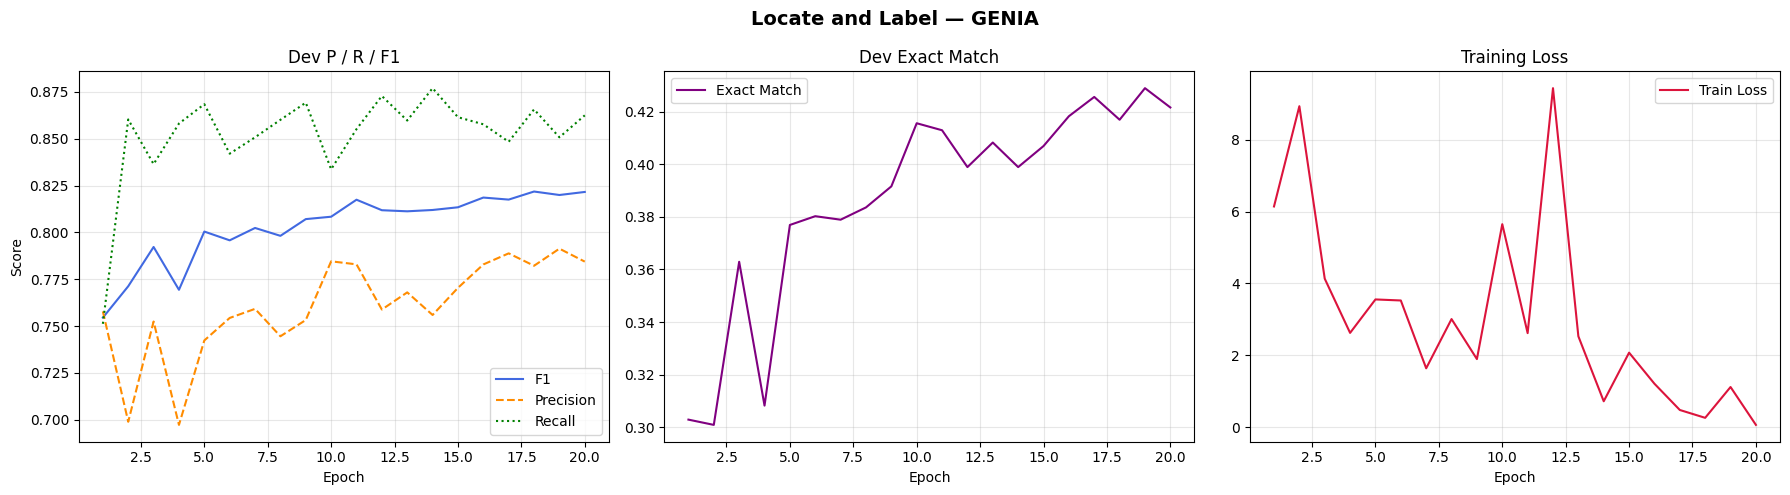

Curves saved to locate_and_label_curves.png


In [19]:
try:
    import matplotlib.pyplot as plt

    epochs_done = [h["epoch"]      for h in history]
    f1_vals     = [h["f1"]         for h in history]
    prec_vals   = [h["precision"]  for h in history]
    rec_vals    = [h["recall"]     for h in history]
    em_vals     = [h["exact_match"]for h in history]
    loss_vals   = [h["train_loss"] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs_done, f1_vals,   label="F1",        color="royalblue")
    axes[0].plot(epochs_done, prec_vals, label="Precision", color="darkorange", linestyle="--")
    axes[0].plot(epochs_done, rec_vals,  label="Recall",    color="green",      linestyle=":")
    axes[0].set_title("Dev P / R / F1"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Score")

    axes[1].plot(epochs_done, em_vals, label="Exact Match", color="purple")
    axes[1].set_title("Dev Exact Match"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    axes[1].set_xlabel("Epoch")

    axes[2].plot(epochs_done, loss_vals, label="Train Loss", color="crimson")
    axes[2].set_title("Training Loss"); axes[2].legend(); axes[2].grid(True, alpha=0.3)
    axes[2].set_xlabel("Epoch")

    plt.suptitle("Locate and Label — GENIA", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("locate_and_label_curves.png", dpi=150)
    plt.show()
    print("Curves saved to locate_and_label_curves.png")
except ImportError:
    print("matplotlib not installed — skipping curves.")

## 6. Final Evaluation on Development Set

In [20]:
checkpoint = torch.load("locate_and_label_best.pt", map_location=device)
model.load_state_dict(checkpoint["model"])
print(f"Loaded best model from epoch {checkpoint['epoch']}")

overall, per_type = evaluate(model, dev_loader)
print_metrics(overall, per_type, epoch=f"BEST (ep {checkpoint['epoch']})")

Loaded best model from epoch 18



─────────────────────────────────────────────────────────────────
  Epoch BEST (ep 18)  
  Overall  →  P: 0.7822  R: 0.8657  F1: 0.8218  EM: 0.4169
  (TP=4357  FP=1213  FN=676  EM sentences=625/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7327  0.7831  0.7571   603   220   167
  RNA             0.7849  0.8391  0.8111    73    20    14
  cell_line       0.6434  0.7679  0.7001   258   143    78
  cell_type       0.7412  0.8372  0.7863   504   176    98
  protein         0.8170  0.9015  0.8571  2919   654   319
─────────────────────────────────────────────────────────────────


## 7. Final Evaluation on Test Set

In [21]:
print("\n--- FINAL EVALUATION ON TEST SET ---")
overall_test, per_type_test = evaluate(model, test_loader)
print_metrics(overall_test, per_type_test, epoch="TEST SET")



--- FINAL EVALUATION ON TEST SET ---



─────────────────────────────────────────────────────────────────
  Epoch TEST SET  
  Overall  →  P: 0.7510  R: 0.7882  F1: 0.7692  EM: 0.3288
  (TP=4340  FP=1439  FN=1166  EM sentences=532/1618)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7389  0.7488  0.7438   945   334   317
  RNA             0.8198  0.8349  0.8273    91    20    18
  cell_line       0.7222  0.6719  0.6962   299   115   146
  cell_type       0.7022  0.7393  0.7203   448   190   158
  protein         0.7663  0.8291  0.7964  2557   780   527
─────────────────────────────────────────────────────────────────
